In [177]:
from dotenv import load_dotenv
load_dotenv()

True

In [178]:
from langchain_groq import ChatGroq
from pydantic import BaseModel, Field
from langgraph.graph import StateGraph,START,END
from langgraph.types import interrupt, Command
from langgraph.checkpoint.memory import InMemorySaver
from typing import Literal

In [179]:
llm = ChatGroq(model="openai/gpt-oss-120b",streaming="True")

In [180]:
class MailState(BaseModel):
    query: str= ""
    draft: str= ""
    human_feedback: str = ""
    final_response: str = ""


In [181]:
from langgraph.types import interrupt
from typing import Literal

def DraftEmail(state: MailState) -> MailState:
    if state.human_feedback:
        draft = llm.invoke(f"""
            Rewrite this draft email for: {state.query}

            Previously generated draft:
            {state.draft}

            Human feedback to apply:
            {state.human_feedback}

            Return the complete revised email.
        """).content
    else:
        draft = llm.invoke(state.query).content

    state.draft = draft
    return state


def HumanFeedBack(state: MailState) -> MailState:
    feedback = interrupt({
        "draft_email": state.draft,
        "question": "Do you want to continue or re-write the mail?"
    })

    fb = str(feedback or "").strip().lower()

    if fb in ("approved", "ok", "yes", "continue"):
        state.human_feedback = ""
    else:
        state.human_feedback = str(feedback)

    return state

def finalize_node(state: MailState):
    return {
        "final_response": "Email sent successfully"
    }
    
def conditional_routing(state: MailState) -> Literal["draft", "final"]:
    if state.human_feedback:
        return "draft"
    return "final"

In [182]:
graph_builder=StateGraph(MailState)

##node
graph_builder.add_node("draft",DraftEmail)
graph_builder.add_node("human_fb",HumanFeedBack)
graph_builder.add_node("final",finalize_node)

##edges
graph_builder.add_edge(START,"draft")
graph_builder.add_edge("draft","human_fb")
graph_builder.add_conditional_edges("human_fb",conditional_routing)
graph_builder.add_edge("human_fb","final")
graph_builder.add_edge("final",END)

graph=graph_builder.compile(checkpointer=InMemorySaver())




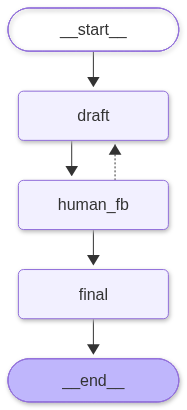

In [183]:
from IPython.display import Image
Image(graph.get_graph().draw_mermaid_png())

In [184]:
config = {"configurable": {"thread_id": "hh-2"}}

res = graph.invoke(
    {
        "query": "Create a simple medical leave request email as a student to the Principal of St. Joseph College, Darjeeling, for 10th November to 15th November."
    },
    config=config
)

print(res["draft"])


**Subject:** Medical Leave Request (10 Nov – 15 Nov)

Dear Principal [Last Name],

I hope you are well. I am writing to inform you that, due to a medical condition, I will be unable to attend classes from **10 November to 15 November**. My doctor has advised me to rest during this period, and I will attach a medical certificate for your reference.

I kindly request your approval for this leave and would be grateful if any assignments or class notes missed during these days could be shared with me so I can catch up promptly.

Thank you for your understanding and support.

Sincerely,  
[Your Full Name]  
[Class/Section]  
St. Joseph College, Darjeeling  
[Phone number / Email address]  


In [185]:
res = graph.invoke(
    Command(resume="Change the principal name to Mr. Ram Kumar Thapa."),
    config=config
)

print(res["final_response"])

InvalidUpdateError: At key 'final_response': Can receive only one value per step. Use an Annotated key to handle multiple values.
For troubleshooting, visit: https://python.langchain.com/docs/troubleshooting/errors/INVALID_CONCURRENT_GRAPH_UPDATE